# 11 · NetworkX visuals — the exploit graph of ThreatGraph

**Goal.** Three figures for the presentation, drawn with **NetworkX**, that show *what the integrated data let us see*: how vulnerabilities are exploited and what they do.

| Figure | Graph | Question |
|---|---|---|
| 1 | bipartite network CVE — exploitation technique | Which techniques are the hubs of exploitation in KEV? |
| 2 | directed network exploitation technique → primary impact | What is the typical attack story? |
| 3 | one CVE across the four sources | What does the integration add for a single vulnerability? |

**Input.** The frozen snapshot **2025-07-28** (CSV tables). No database and no Django needed. Every number drawn is recounted with plain pandas/Python (section 5), and compared with the numbers of notebook 08.

**Scope.** The ATT&CK mappings come from CTID PKEV and cover **419 of 1,391** KEV CVEs. Figures 1–3 describe these mapped CVEs only. A missing mapping means *not mapped*, not *no technique applies*.

## 0 · Setup

In [1]:
import sys, json, textwrap, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "sources.yaml").exists())
sys.path[:0] = [str(ROOT / "src")]
import numpy as np, pandas as pd, networkx as nx
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from threatgraph import config, snapshot as SN
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30, "display.max_colwidth", 60, "display.width", 200)

LABEL = config.load_sources()["common_version"]["label"]; BASE = config.SNAPSHOT_DIR / LABEL
assert SN.verify_snapshot(BASE) == [], "baseline snapshot damaged or missing (run notebook 06 / snapshot_db)"
T = SN.read_tables(BASE)                                   # 9 tables, all strings
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
checks = []
def check(name, ok, detail=""):
    checks.append({"name": name, "ok": bool(ok), "detail": str(detail)[:160]}); print("OK  " if ok else "FAIL", name, detail); return bool(ok)

# paper style (same palette as notebook 08)
INK, INK2, GRAY = "#0b0b0b", "#52514e", "#b9b8b1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
mpl.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 9.5, "text.color": INK,
                     "axes.edgecolor": INK2, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); fig.savefig(FIG / f"{name}.pdf"); plt.show(); print("saved:", FIG / f"{name}.png")
print("snapshot:", LABEL, "| content_id:", SN.read_manifest(BASE)["content_id"][:16] + "…")

snapshot: 2025-07-28 | content_id: 74d833caed5fc336…


## 1 · Data for the graphs

Only three kinds of facts are needed: the CVEs and their ransomware flag (KEV), the technique names (ATT&CK), and the PKEV mappings (`exploitation_technique`, `primary_impact`, `secondary_impact`).

In [2]:
kev, mp, tech = T["kev_vulnerability"], T["pkev_mapping"], T["attack_technique"]
Tn = dict(zip(tech.technique_id, tech.name))
RANSOM = set(kev.loc[kev.ransomware_use == "known", "cve_id"])
ex = mp.loc[mp.mapping_type == "exploitation_technique", ["cve_id", "technique_id"]].drop_duplicates()
im = mp.loc[mp.mapping_type == "primary_impact", ["cve_id", "technique_id"]].drop_duplicates()
display(mp.mapping_type.value_counts().rename("mappings").to_frame())
print(f"KEV CVEs: {len(kev):,} | mapped CVEs: {mp.cve_id.nunique()} | exploitation links: {len(ex)} | CVEs with an exploitation technique: {ex.cve_id.nunique()}")

,mappings
mapping_type,
exploitation_technique,460
primary_impact,407
secondary_impact,316


KEV CVEs: 1,391 | mapped CVEs: 419 | exploitation links: 460 | CVEs with an exploitation technique: 405


## 2 · Figure 1 — The exploit network

**Graph.** Bipartite: a **CVE** node is linked to the **technique** node used to exploit it (PKEV role `exploitation_technique`). Technique size = number of CVEs (degree). CVE colour = ransomware use known in KEV (orange) or not (gray). Layout: Fruchterman–Reingold spring layout, fixed seed (reproducible).

**What to look for.** A few technique hubs with many CVEs around them, and many techniques with only one or two.

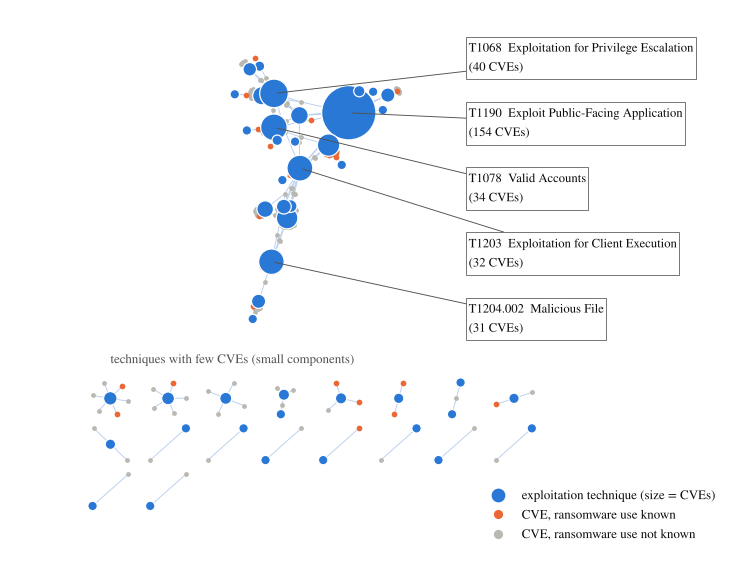

saved: /home/claude/threatgraph-ld/docs/figures/fig11_1_exploit_network.png
Insight: T1190 (Exploit Public-Facing Application) is the largest hub with 154 CVEs; the 5 largest hubs hold 291 of 460 exploitation links (63%).


In [3]:
G1 = nx.Graph()
G1.add_edges_from((("CVE", c), ("TECH", t)) for c, t in ex.itertuples(index=False))
techs = [n for n in G1 if n[0] == "TECH"]; cves = [n for n in G1 if n[0] == "CVE"]
deg = {n: G1.degree(n) for n in techs}
hubs = sorted(techs, key=lambda n: -deg[n])[:5]
comps = sorted(nx.connected_components(G1), key=len, reverse=True)
big = G1.subgraph(comps[0])
pos = dict(nx.spring_layout(big, k=1.1 / np.sqrt(len(big)), iterations=500, seed=42, scale=1.0))
for i, comp in enumerate(comps[1:]):                     # small components: packed on a grid below the main block
    q = nx.spring_layout(G1.subgraph(comp), seed=1, scale=0.09)
    cx, cy = -1.0 + (i % 8) * 0.29, -1.45 - (i // 8) * 0.26
    pos.update({n: (x + cx, y + cy) for n, (x, y) in q.items()})
cen = np.mean([pos[n] for n in big], axis=0)

fig, ax = plt.subplots(figsize=(8.4, 6.4)); ax.axis("off")
nx.draw_networkx_edges(G1, pos, ax=ax, edge_color="#b9cfee", width=0.6)
ransom_c = [n for n in cves if n[1] in RANSOM]; other_c = [n for n in cves if n[1] not in RANSOM]
nx.draw_networkx_nodes(G1, pos, ax=ax, nodelist=other_c, node_size=10, node_color=GRAY, linewidths=0)
nx.draw_networkx_nodes(G1, pos, ax=ax, nodelist=ransom_c, node_size=14, node_color=ORANGE, linewidths=0)
nx.draw_networkx_nodes(G1, pos, ax=ax, nodelist=techs, node_size=[30 + 8 * deg[n] for n in techs], node_color=BLUE, edgecolors="white", linewidths=0.8)
xr = max(pos[n][0] for n in big) + 0.35                    # label column to the right of the main block
ys = [pos[n][1] for n in big]; ytop, ybot = max(ys), min(ys)
order = sorted(hubs, key=lambda n: -pos[n][1])                # sorted by height, so leader lines do not cross
for n, yl in zip(order, np.linspace(ytop, ybot, len(order))):
    ax.annotate(f"{n[1]}  {Tn[n[1]]}\n({deg[n]} CVEs)", xy=pos[n], xytext=(xr, yl), textcoords="data", ha="left", va="center", fontsize=8.3,
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6, shrinkA=0, shrinkB=2), bbox=dict(fc="white", ec=INK2, lw=0.5, pad=1.5), zorder=6)
ax.text(-1.0, -1.25, "techniques with few CVEs (small components)", fontsize=8.5, color=INK2, ha="left")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, ms=8, label="exploitation technique (size = CVEs)"),
                   Line2D([], [], marker="o", ls="", color=ORANGE, ms=5, label="CVE, ransomware use known"),
                   Line2D([], [], marker="o", ls="", color=GRAY, ms=5, label="CVE, ransomware use not known")],
          loc="lower right", frameon=False, fontsize=8.5)
ax.set_xlim(-1.5, xr + 1.3)
save(fig, "fig11_1_exploit_network")
print(f"Insight: {hubs[0][1]} ({Tn[hubs[0][1]]}) is the largest hub with {deg[hubs[0]]} CVEs; the 5 largest hubs hold "
      f"{sum(deg[n] for n in hubs)} of {len(ex)} exploitation links ({sum(deg[n] for n in hubs)/len(ex):.0%}).")

*Figure 1. Exploit network of the mapped KEV vulnerabilities. Each CVE is linked to the ATT&CK technique that PKEV gives as its exploitation technique. Blue = technique (size = number of CVEs), orange/gray = CVE with/without known ransomware use. Labels: five largest hubs. Only the CVEs mapped by PKEV appear (419 of 1,391 KEV CVEs; not every mapped CVE has an exploitation technique).*

## 3 · Figure 2 — From exploit to impact

**Graph.** Directed: an edge goes from the **exploitation technique** to the **primary-impact technique** of the *same CVE*. Edge width and label = number of CVEs sharing that pair (pairs with at least 5 CVEs). Only the CVEs that have **both** roles mapped can appear.

**What to look for.** The widest edge is the most common "attack story" in KEV.

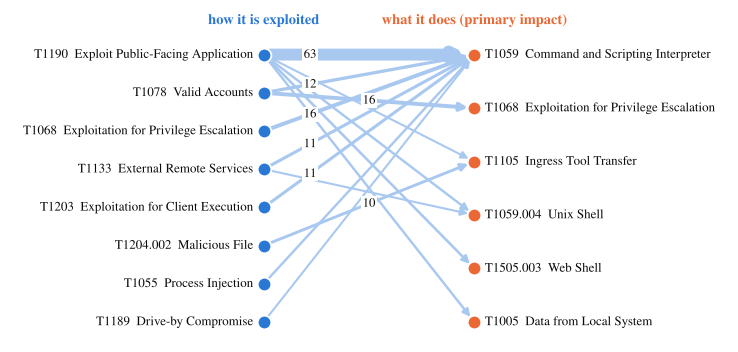

saved: /home/claude/threatgraph-ld/docs/figures/fig11_2_exploit_to_impact.png
Insight: the most common story is T1190 (Exploit Public-Facing Application) followed by T1059 (Command and Scripting Interpreter): 63 CVEs, 18% of the 345 CVEs with both roles mapped.


In [4]:
pairs = ex.merge(im, on="cve_id", suffixes=("_x", "_i"))
flow = pairs.groupby(["technique_id_x", "technique_id_i"]).cve_id.nunique().sort_values(ascending=False)
flow5 = flow[flow >= 5]
G2 = nx.DiGraph(); G2.add_weighted_edges_from((f"x:{a}", f"i:{b}", int(n)) for (a, b), n in flow5.items())
xs = sorted([n for n in G2 if n[0] == "x"], key=lambda n: -G2.out_degree(n, weight="weight"))
is_ = sorted([n for n in G2 if n[0] == "i"], key=lambda n: -G2.in_degree(n, weight="weight"))
pos2 = {n: (0.0, -i) for i, n in enumerate(xs)} | {n: (1.0, -i * max(len(xs) - 1, 1) / max(len(is_) - 1, 1)) for i, n in enumerate(is_)}

fig, ax = plt.subplots(figsize=(8.4, 3.9)); ax.axis("off")
w = np.array([G2[u][v]["weight"] for u, v in G2.edges])
nx.draw_networkx_edges(G2, pos2, ax=ax, width=0.8 + 7.0 * w / w.max(), edge_color="#a9c8f0", arrows=True, arrowstyle="-|>", arrowsize=10, node_size=70)
nx.draw_networkx_nodes(G2, pos2, ax=ax, nodelist=xs, node_color=BLUE, node_size=80, edgecolors="white", linewidths=1.2)
nx.draw_networkx_nodes(G2, pos2, ax=ax, nodelist=is_, node_color=ORANGE, node_size=80, edgecolors="white", linewidths=1.2)
for n in xs:  ax.text(pos2[n][0] - 0.05, pos2[n][1], f"{n[2:]}  {textwrap.shorten(Tn[n[2:]], 38, placeholder='…')}", ha="right", va="center", fontsize=8.5)
for n in is_: ax.text(pos2[n][0] + 0.05, pos2[n][1], f"{n[2:]}  {textwrap.shorten(Tn[n[2:]], 38, placeholder='…')}", ha="left", va="center", fontsize=8.5)
for (u, v), wv in zip(G2.edges, w):
    if wv >= 10:   # label only the larger flows; edges that converge on one target are labelled near their source
        tl = 0.22 if v == is_[0] else 0.5
        ax.text(pos2[u][0] + tl * (pos2[v][0] - pos2[u][0]), pos2[u][1] + tl * (pos2[v][1] - pos2[u][1]), int(wv), ha="center", va="center",
                fontsize=8.3, bbox=dict(fc="white", ec="none", pad=0.8), zorder=4)
ax.text(0, 0.8, "how it is exploited", ha="center", fontsize=9.5, fontweight="bold", color=BLUE)
ax.text(1, 0.8, "what it does (primary impact)", ha="center", fontsize=9.5, fontweight="bold", color=ORANGE)
ax.set_xlim(-1.2, 2.2); ax.set_ylim(min(p[1] for p in pos2.values()) - 0.5, 1.15)
save(fig, "fig11_2_exploit_to_impact")
(a, b), n_top = flow.index[0], int(flow.iloc[0]); n_both = pairs.cve_id.nunique()
print(f"Insight: the most common story is {a} ({Tn[a]}) followed by {b} ({Tn[b]}): {n_top} CVEs, {n_top/n_both:.0%} of the {n_both} CVEs with both roles mapped.")

*Figure 2. Directed network from the exploitation technique to the primary-impact technique of the same CVE (pairs shared by at least 5 CVEs; edge width and labels = number of CVEs, labels from 10). Built from PKEV: only CVEs with both roles mapped are included.*

## 4 · Figure 3 — One vulnerability, four sources

**Graph.** One CVE and everything the integrated database says about it. Layers from left to right: source facts (KEV, NVD, CWE) → the CVE → ATT&CK techniques (from PKEV) → ATT&CK tactics. Colour = source: KEV blue, NVD orange, weakness gray, ATT&CK/PKEV aqua. The function `case_graph(cve_id)` draws the same figure for any CVE.

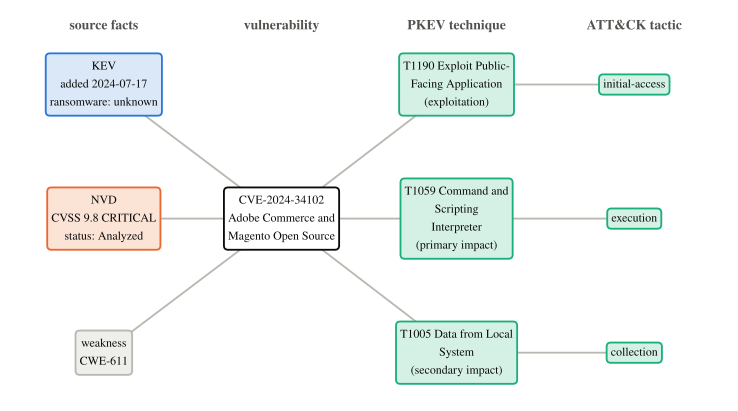

saved: /home/claude/threatgraph-ld/docs/figures/fig11_3_case_study.png
Insight: CVE-2024-34102 (Adobe Commerce and Magento Open Source) is one node with facts from four sources: exploited (KEV), CVSS 9.8 (NVD), 3 PKEV mapping(s), 3 ATT&CK tactic(s).


In [5]:
nvd, kcwe, ncwe = T["nvd_cve"], T["kev_cwe"], T["nvd_cve_cwe"]
tt, tac = T["attack_technique_tactic"], T["attack_tactic"]
TAC = dict(zip(tac.tactic_id, tac.shortname))
ROLE = {"exploitation_technique": "exploitation", "primary_impact": "primary impact", "secondary_impact": "secondary impact"}

def case_graph(cve_id):
    k = kev[kev.cve_id == cve_id].iloc[0]; n = nvd[nvd.cve_id == cve_id].iloc[0]
    cwes = sorted(set(kcwe.loc[kcwe.cve_id == cve_id, "cwe_id"]) | set(ncwe.loc[ncwe.cve_id == cve_id, "cwe_id"]))
    maps = mp[mp.cve_id == cve_id].sort_values(["mapping_type", "technique_id"])
    G = nx.DiGraph(); lab, col, layer = {}, {}, {}
    def add(node, text, c, l): lab[node] = text; col[node] = c; layer[node] = l; G.add_node(node, layer=l)
    add("cve", f"{cve_id}\n" + "\n".join(textwrap.wrap(f"{k["vendor_project"]} {k["product"]}", 22)), "white", 1)
    add("kev", f"KEV\nadded {k.date_added}\nransomware: {k.ransomware_use}", "#dbe8f7", 0); G.add_edge("kev", "cve")
    add("nvd", f"NVD\nCVSS {n.cvss_v31_score} {n.cvss_v31_severity}\nstatus: {n.vuln_status}", "#fbe3d6", 0); G.add_edge("nvd", "cve")
    for c in cwes: add("cwe:" + c, f"weakness\n{c}", "#eeeeea", 0); G.add_edge("cwe:" + c, "cve")
    for r in maps.itertuples():
        t = "t:" + r.technique_id
        if t not in G: add(t, f"{r.technique_id} " + "\n".join(textwrap.wrap(Tn[r.technique_id], 20)) + f"\n({ROLE[r.mapping_type]})", "#d5f1e6", 2)
        G.add_edge("cve", t)
        for tid in tt.loc[tt.technique_id == r.technique_id, "tactic_id"]:
            a = "a:" + TAC[tid]
            if a not in G: add(a, TAC[tid], "#d5f1e6", 3)
            G.add_edge(t, a)
    return G, lab, col, maps, k, n, cwes

CASE = "CVE-2024-34102"
G3, lab, col, maps, k, n, cwes = case_graph(CASE)
LX = [-1.0, -0.33, 0.33, 1.0]; pos3 = {}
for l in range(4):                                         # nodes keep insertion order inside each layer, top to bottom
    nodes_l = [n_ for n_ in G3 if G3.nodes[n_]["layer"] == l]
    ys_l = [0.0] if len(nodes_l) == 1 else list(np.linspace(0.85, -0.85, len(nodes_l)))
    pos3.update({n_: (LX[l], y_) for n_, y_ in zip(nodes_l, ys_l)})
fig, ax = plt.subplots(figsize=(8.4, 4.6)); ax.axis("off")
texts = {}
for node, (x, y) in pos3.items():
    ec = {0: {"kev": BLUE, "nvd": ORANGE}.get(node, GRAY), 1: INK, 2: AQUA, 3: AQUA}[G3.nodes[node]["layer"]]
    texts[node] = ax.text(x, y, lab[node], ha="center", va="center", fontsize=7.8, zorder=3, bbox=dict(boxstyle="round,pad=0.35", fc=col[node], ec=ec, lw=1.2))
fig.canvas.draw()                                         # boxes must exist before arrows can stop at their borders
for u, v in G3.edges:
    ax.annotate("", xy=pos3[v], xytext=pos3[u], zorder=2,
                arrowprops=dict(arrowstyle="-", color=GRAY, lw=1.2, shrinkA=0, shrinkB=0,
                                patchA=texts[u].get_bbox_patch(), patchB=texts[v].get_bbox_patch()))
for x, t in zip(LX, ["source facts", "vulnerability", "PKEV technique", "ATT&CK tactic"]):
    ax.text(x, 1.2, t, ha="center", fontsize=9, fontweight="bold", color=INK2)
ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.15, 1.32)
save(fig, "fig11_3_case_study")
print(f"Insight: {CASE} ({k["vendor_project"]} {k["product"]}) is one node with facts from four sources: exploited (KEV), CVSS {n.cvss_v31_score} (NVD), "
      f"{len(maps)} PKEV mapping(s), {sum(1 for x in G3 if x.startswith('a:'))} ATT&CK tactic(s).")

*Figure 3. One vulnerability across the four integrated sources. Left: attributes from KEV, NVD and the weakness list (CWE). Centre: the CVE, the shared key. Right: the ATT&CK techniques that PKEV assigns to it and the tactics (attacker goals) of those techniques.*

## 5 · Graph metrics and independent checks

The figures must not be decoration. Below: (a) simple network measures computed with NetworkX; (b) every number drawn is **recounted without NetworkX** and compared with the numbers of notebook 08 (`docs/results_key_numbers.json`).

In [6]:
comp = sorted(nx.connected_components(G1), key=len, reverse=True)
tdeg = pd.Series({n[1]: deg[n] for n in techs}).sort_values(ascending=False)
metrics = pd.DataFrame({"value": {
    "nodes (CVEs + techniques)": G1.number_of_nodes(), "  of which CVEs": len(cves), "  of which techniques": len(techs),
    "edges (exploitation links)": G1.number_of_edges(), "connected components": len(comp),
    "largest component (share of nodes)": f"{len(comp[0]) / G1.number_of_nodes():.0%}",
    "techniques used by 1 CVE only": int((tdeg == 1).sum()), "top-5 hubs: share of links": f"{tdeg.head(5).sum() / len(ex):.0%}"}})
display(metrics)
display(tdeg.head(5).rename("CVEs").to_frame().assign(name=lambda d: [Tn[i] for i in d.index]))

,value
nodes (CVEs + techniques),451
of which CVEs,405
of which techniques,46
edges (exploitation links),460
connected components,19
largest component (share of nodes),87%
techniques used by 1 CVE only,20
top-5 hubs: share of links,63%


,CVEs,name
T1190,154,Exploit Public-Facing Application
T1068,40,Exploitation for Privilege Escalation
T1078,34,Valid Accounts
T1203,32,Exploitation for Client Execution
T1204.002,31,Malicious File


In [7]:
KEYN = json.loads((ROOT / "docs" / "results_key_numbers.json").read_text())
# Figure 1: independent recount (plain Python, no NetworkX)
links = set(map(tuple, ex.itertuples(index=False)))
per_tech = {}
for c, t in links: per_tech.setdefault(t, set()).add(c)
check("Fig.1: edges == distinct (CVE, technique) pairs", G1.number_of_edges() == len(links))
check("Fig.1: degree of every technique == recount", all(deg[("TECH", t)] == len(cs) for t, cs in per_tech.items()))
check("Fig.1: CVE nodes == CVEs with an exploitation mapping", len(cves) == len({c for c, _ in links}))
check("Fig.1: every CVE node exists in KEV", {c[1] for c in cves} <= set(kev.cve_id))
check("Fig.1: ransomware colour == KEV flag", {n[1] for n in ransom_c} == {c for c in {n[1] for n in cves} if c in set(kev.loc[kev.ransomware_use == 'known', 'cve_id'])})
# Figure 2: independent recount of the widest edge
exd, imd = {}, {}
for c, t in ex.itertuples(index=False): exd.setdefault(c, set()).add(t)
for c, t in im.itertuples(index=False): imd.setdefault(c, set()).add(t)
cnt = {}
for c in set(exd) & set(imd):
    for a_ in exd[c]:
        for b_ in imd[c]: cnt[(a_, b_)] = cnt.get((a_, b_), 0) + 1
check("Fig.2: widest edge == recount", cnt[(a, b)] == n_top == max(cnt.values()), f"{a}->{b}: {n_top}")
check("Fig.2: every drawn edge weight == recount", all(G2[u][v]["weight"] == cnt[(u[2:], v[2:])] for u, v in G2.edges))
check("Fig.2: CVEs with both roles == recount", n_both == len(set(exd) & set(imd)), n_both)
# Figure 3: values drawn == raw table rows
raw_k = kev.set_index("cve_id").loc[CASE]; raw_n = nvd.set_index("cve_id").loc[CASE]
check("Fig.3: KEV and NVD values on the figure == raw rows", str(raw_n.cvss_v31_score) in lab["nvd"] and raw_k.date_added in lab["kev"] and raw_k.ransomware_use in lab["kev"])
check("Fig.3: number of technique nodes == distinct PKEV techniques of the CVE", sum(1 for x in G3 if x.startswith("t:")) == mp.loc[mp.cve_id == CASE, "technique_id"].nunique())
check("Fig.3: the CVE has all four sources (KEV, NVD, >=1 PKEV mapping, >=1 tactic)", len(maps) >= 1 and any(x.startswith("a:") for x in G3))
# consistency with notebook 08 (same snapshot, other code path)
check("08: 1,183 PKEV mappings", len(mp) == KEYN["n_mappings"], len(mp))
check("08: 419 mapped CVEs", mp.cve_id.nunique() == KEYN["n_mapped"], mp.cve_id.nunique())
check("08: 345 CVEs with both roles", n_both == KEYN["n_both_roles"], n_both)
check("08: T1059 used by 170 CVEs (all roles)", mp.loc[mp.technique_id == KEYN["top_tech"], "cve_id"].nunique() == KEYN["top_tech_n"])
check("figure files exist", all((FIG / f"fig11_{s}.png").stat().st_size > 20_000 for s in ("1_exploit_network", "2_exploit_to_impact", "3_case_study")))
res = pd.DataFrame(checks); print(f"\n{res.ok.sum()}/{len(res)} checks passed"); assert res.ok.all(), res[~res.ok]

OK   Fig.1: edges == distinct (CVE, technique) pairs 
OK   Fig.1: degree of every technique == recount 
OK   Fig.1: CVE nodes == CVEs with an exploitation mapping 
OK   Fig.1: every CVE node exists in KEV 


OK   Fig.1: ransomware colour == KEV flag 
OK   Fig.2: widest edge == recount T1190->T1059: 63
OK   Fig.2: every drawn edge weight == recount 
OK   Fig.2: CVEs with both roles == recount 345
OK   Fig.3: KEV and NVD values on the figure == raw rows 
OK   Fig.3: number of technique nodes == distinct PKEV techniques of the CVE 
OK   Fig.3: the CVE has all four sources (KEV, NVD, >=1 PKEV mapping, >=1 tactic) 
OK   08: 1,183 PKEV mappings 1183
OK   08: 419 mapped CVEs 419
OK   08: 345 CVEs with both roles 345
OK   08: T1059 used by 170 CVEs (all roles) 
OK   figure files exist 

16/16 checks passed


## 6 · How to read these figures — and their limits

* **Selection.** KEV lists only vulnerabilities with evidence of exploitation that CISA chose to list. The figures describe KEV, not all CVEs.
* **Coverage.** PKEV maps 419 of 1,391 CVEs (30%). Hubs may reflect *what was mapped*, not what attackers do. Absence of a mapping is "not mapped".
* **Layout is not data.** In Figure 1 the position of nodes comes from a layout algorithm (fixed seed); only size, colour and links carry information. Distances are not measurements.
* **Graph measures are descriptive.** Hub size is a count of CVEs; no causal claim is made.
* **Integration value.** Figure 3 is possible only because the four sources share the `CVE` key and the technique code: this is the point of the data-management work, not the attack statistics themselves.